# Lab SVM

# Leny Tacuri

# Repositorio: 



# 📔 **Resolución**
Una vez que la nota sea entregada, encontrarás la resolución en este link de notion:

https://www.notion.so/R-SVM-Lab-Churn-5e7b5abf68f94dda96264ef41e1b5fae?source=copy_link

Recuerda que existen varias formar de solucionar las actividades propuestas en los laboratorios. Toma la resolución entregada como referencia. En caso de que el link de resolución no esté público, solicita acceso en el mismo link de notion.|

# Predicción de pérdida de clientes en Empresas de Servicios de Telecomunicaciones (Churn)

Reducir las salidas y [deserciones de clientes](https://www.bain.com/insights/breaking-the-back-of-customer-churn/) se ha convertido en una alta prioridad para la mayoría de los proveedores de servicios de comunicaciones a medida que los mercados maduran y la competencia se intensifica.




En este documento usaremos una base de datos de una empresa de telecomunicaciones anónima [disponibilizada por IBM](https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv).

El principal objetivo es crear un model de aprendizaje automático basado en SVM y Regresión Logística (Logistic Regression, LR) para predecir la pérdida o salida de clientes en una empresa de telecomunicaciones.


## Librerías

In [1]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split


## Base de datos

Este conjunto de datos contiene un total de 7043 clientes y 21 características de los mismos. De las entradas, 5174 son clientes activos y 1869 son clientes que la empresa ha perdido. Observe que el conjunto de datos está desbalanceado pues por cada cliente perdido existe casi 3 clientes activos. La variable de salida para nuestro modelo de machine learning será `Churn`.

In [2]:
# importamos dataset
DATA_PATH = "https://raw.githubusercontent.com/carlosfab/dsnp2/master/datasets/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(DATA_PATH)

# vemos las primeras 5 filas
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### *Detalles de la base de datos*

*	`customerID` - Custumer unique identifier
*	`gender` - Customer gender - ['Female' 'Male']
*	`SeniorCitizen` - Elderly or retired person, a senior citizen is someone who has at least attained the age of 60 of 65 years
*	`Partner` - - ['No' 'Yes']
*	`Dependents` - If customer has dependents - ['No' 'Yes']
*	`Tenure` - Customer lifespan (in months)
*	`PhoneService` - - ['No' 'Yes']
*	`MultipleLines` - - ['No' 'No phone service' 'Yes']
*	`InternetService` - - ['No' 'No internet service' 'Yes']
*	`OnlineSecurity` - - ['No' 'No internet service' 'Yes']
*	`OnlineBackup` - - ['No' 'No internet service' 'Yes']
*	`DeviceProtection` - - ['No' 'No internet service' 'Yes']
*	`TechSupport` - - ['No' 'No internet service' 'Yes']
*	`StreamingTV` - - ['No' 'No internet service' 'Yes']
*	`StreamingMovies` -  - ['No' 'No internet service' 'Yes']
*	`Contract` - Type of contract - ['Month-to-month' 'One year' 'Two year']
*	`PaperlessBilling` - - ['No' 'Yes']
*	`PaymentMethod` - payment method - ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
*	`MonthlyCharges` - Monthly Recurring Charges
*	`TotalCharges` - Life time value
*	`Churn` - Churn value, the targer vector - ['No' 'Yes']





### *Limpieza del Dataset*

La función get_df_size se utiliza para obtener información básica sobre el tamaño del conjunto de datos, en términos de su número de atributos y entradas.

Luego, se reemplazan los valores en blanco por NaN (valores faltantes) en el dataframe utilizando la función replace de pandas. Se reemplazan los valores faltantes en la columna TotalCharges por la mediana de los valores no faltantes de la misma columna, utilizando la función fillna de pandas. Además, se convierte esta columna de tipo objeto a tipo numérico utilizando la función apply de pandas y el método pd.to_numeric.

A continuación, se elimina la columna customerID, ya que no es una característica relevante para el modelo. Se utiliza el método drop de pandas para eliminar la columna, especificando el argumento axis=1 para indicar que se está eliminando una columna y no una fila.

Por último, se utiliza la función describe de pandas para obtener estadísticas descriptivas del conjunto de datos preprocesado y se imprimen en pantalla la cantidad de instancias con valor "Yes" y "No" en la variable objetivo Churn.

In [3]:
def get_df_size(df, header='Dataset dimensions'):
  print(header,
        '\n# Attributes: ', df.shape[1],
        '\n# Entries: ', df.shape[0],'\n')

get_df_size(df)

#df.info()

# reemplaza valores en blanco por NaN
df_clean = df.replace(r'^\s*$', np.nan, regex=True)


# Convert 'TotalCharges' to numeric before calculating the median.
# errors='coerce' will handle any non-numeric values by setting them to NaN.
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')

# reemplaza valores faltantes en TotalCharges por la mediana de TotalCharges.
total_charges_median = df_clean.TotalCharges.median()


df_clean['TotalCharges'].fillna(total_charges_median, inplace=True)
df_clean['TotalCharges'] = df_clean['TotalCharges'].apply(pd.to_numeric)

#CustomerID lo retiramos porque no es una característica
df_clean = df_clean.drop('customerID', axis=1)
df_clean.describe()

print("Churn No Instances: ", df_clean[df_clean['Churn'] == 'No'].shape[0])
print("Churn Yes Instances: ", df_clean[df_clean['Churn'] == 'Yes'].shape[0])


Dataset dimensions 
# Attributes:  21 
# Entries:  7043 

Churn No Instances:  5174
Churn Yes Instances:  1869


/var/folders/9p/t_k24wrx3rv55clz4x0qkc2h0000gn/T/ipykernel_56114/1680099738.py:22: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean['TotalCharges'].fillna(total_charges_median, inplace=True)


## Preparación de la Base de Datos








Este código realiza la preprocesamiento de los datos en el dataframe df_clean para poder usarlo en un modelo de machine learning. En primer lugar, identifica las características binarias, numéricas y categóricas en el conjunto de datos. Luego, crea una copia del dataframe original y realiza las siguientes operaciones sobre él:

Convierte las características binarias en etiquetas numéricas mediante el uso de LabelEncoder().
Crea variables dummy para las características categóricas usando pd.get_dummies().
Imprime la información del tamaño del conjunto de datos original y procesado utilizando la función get_df_size().
Retorna un nuevo dataframe df_proc que contiene todas las características preprocesadas y que puede ser utilizado en un modelo de machine learning.
En resumen, el código realiza la limpieza, transformación y preparación de los datos para su posterior uso en un modelo de machine learning.

In [4]:
binary_feat = df_clean.nunique()[df_clean.nunique() == 2].keys().tolist()
numeric_feat = [col for col in df_clean.select_dtypes(['float','int']).columns.tolist() if col not in binary_feat]
categorical_feat = [ col for col in df_clean.select_dtypes('object').columns.to_list() if col not in binary_feat + numeric_feat ]
df_proc = df_clean.copy()
#Etiquetas para características binarias
le = LabelEncoder()
for i in binary_feat:
  df_proc[i] = le.fit_transform(df_proc[i])
  print(i, '\n', np.unique(df_proc[i].values))
#Dummy variables
df_proc = pd.get_dummies(df_proc, columns=categorical_feat)
get_df_size(df, header='Original dataset:')
get_df_size(df_proc, header='Processed dataset:')
df_proc.head()

gender 
 [0 1]
SeniorCitizen 
 [0 1]
Partner 
 [0 1]
Dependents 
 [0 1]
PhoneService 
 [0 1]
PaperlessBilling 
 [0 1]
Churn 
 [0 1]
Original dataset: 
# Attributes:  21 
# Entries:  7043 

Processed dataset: 
# Attributes:  41 
# Entries:  7043 



,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,True,False,False,True,False,False,False,False,True,False
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,True,False,False,False,True,False,False,False,False,True
2,1,0,0,0,2,1,1,53.85,108.15,1,...,True,False,False,True,False,False,False,False,False,True
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,True,False,False,False,True,False,True,False,False,False
4,0,0,0,0,2,1,1,70.70,151.65,1,...,True,False,False,True,False,False,False,False,True,False


### *División en conjunto de entrenamiento y test*

In [5]:
# dividimos df_proc en características y salida
X=df_proc.drop('Churn', axis=1)
y=df_proc['Churn']

# Dividimos el conjunto de entrenamiento y test
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

### ✅ Actividad 1: Visualización con TSNE
Utilice TSNE para visualizar su dataset de entrenamiento. Recuerde normalizar su dasaset (zscore) antes de esta y las siguientes actividades.

#### Estandarización y proyección a dos dimensiones

Aplicamos **z-score** con `StandardScaler`: cada característica se centra en su media y se divide entre su desviación estándar. Ajustamos el escalador únicamente con `X_train`; para test utilizamos las mismas estadísticas.

Después, t-SNE proyecta las características de entrenamiento a dos dimensiones. La variable `Churn` se utiliza únicamente para colorear los puntos, no para calcular la proyección.

Entrenamiento estandarizado: (5634, 40)
Test estandarizado: (1409, 40)


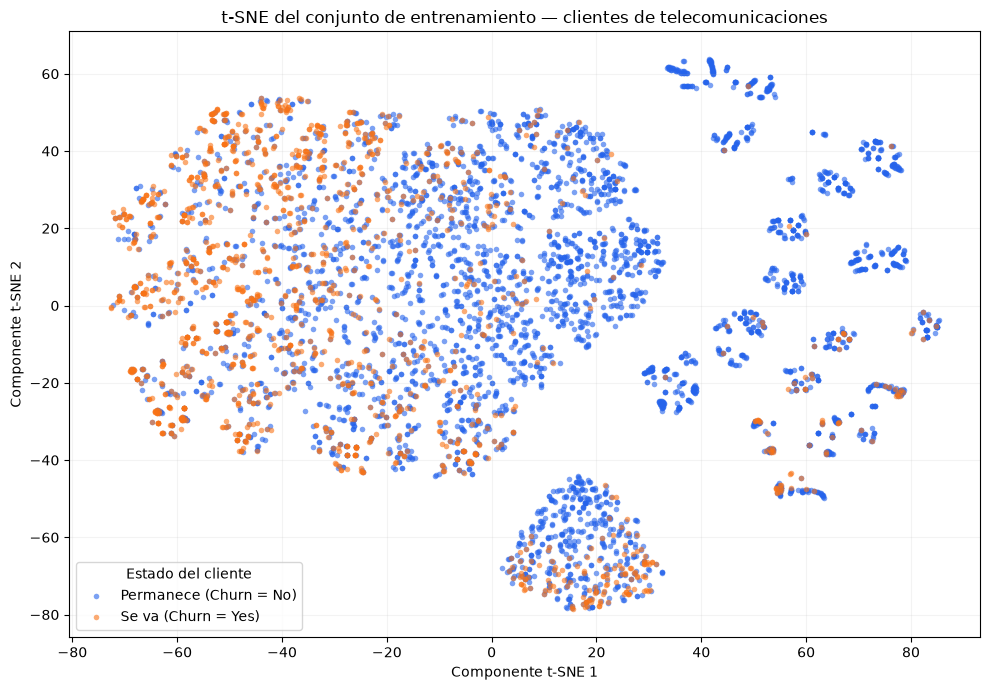

In [6]:
from sklearn.manifold import TSNE

# Ajustar únicamente con entrenamiento para no usar estadísticas del test.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Entrenamiento estandarizado: {X_train_scaled.shape}")
print(f"Test estandarizado: {X_test_scaled.shape}")

# t-SNE se aplica solo al conjunto de entrenamiento.
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42,
)
X_train_tsne = tsne.fit_transform(X_train_scaled)

fig, ax = plt.subplots(figsize=(10, 7))
for clase, etiqueta, color in [
    (0, "Permanece (Churn = No)", "#2563eb"),
    (1, "Se va (Churn = Yes)", "#f97316"),
]:
    mask = y_train.to_numpy() == clase
    ax.scatter(
        X_train_tsne[mask, 0], X_train_tsne[mask, 1],
        label=etiqueta, c=color, s=16, alpha=0.6, linewidths=0,
    )

ax.set(
    title="t-SNE del conjunto de entrenamiento — clientes de telecomunicaciones",
    xlabel="Componente t-SNE 1",
    ylabel="Componente t-SNE 2",
)
ax.legend(title="Estado del cliente")
ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()


**Cómo interpretar el gráfico:** cada punto representa un cliente. Los vecindarios ayudan a explorar similitudes entre clientes y la mezcla de las dos clases. Los ejes no corresponden a variables originales; las distancias entre grupos alejados y sus tamaños no deben interpretarse como medidas directas del dataset. Esta visualización no mide el rendimiento de un clasificador.

Para las siguientes actividades se usarán las características originales estandarizadas, no las dos coordenadas de t-SNE. Durante la validación cruzada, el escalador debe ir dentro de un `Pipeline` para ajustarse en cada fold de entrenamiento.

### ✅ Actividad 2: Clasificador y Optimización de Hiperparámetros SVM

Cree un clasificador con SVM (ver `SVC`) con kernel RBF.
Use 5-fold cross-validation (ver `GridSearchCV` y  `StratifiedKFold`) para optimizar los siguientes hiperparámetros en el conjunto de entrenamiento (`X_train`, `y_train`):

1. Gamma
2. C


Para la optimización de hiperparámetros utilice como métrica al recall.

Grafique con un mapa de calor 2D donde el eje x es Gamma, el eje y es C y el color es el score.

Una vez optimizados los hiperparámetros, reentrene su clasificador con los mejores hiperparámetros encontrados. Finalmente, evalúe este último clasificador en el conjunto de test ('X_test', 'y_test'.)




#### Búsqueda de hiperparámetros con validación cruzada

Usamos `StratifiedKFold(n_splits=5)` para mantener aproximadamente la proporción de clientes que se van en cada partición. Probamos 20 combinaciones de **C** y **gamma**, con 5 evaluaciones por combinación (100 ajustes), y seleccionamos el mayor **recall de Churn = Yes**.

El `Pipeline` calcula la imputación y el z-score en cada fold de entrenamiento. Como el código inicial imputó `TotalCharges` antes de dividir los datos, recuperamos sus valores faltantes del dataset original para que esa mediana también se calcule dentro de cada fold. No usamos las coordenadas t-SNE como entradas al modelo.

`refit=True` reentrena automáticamente la mejor configuración con todo el conjunto de entrenamiento. El test se reserva para la evaluación final.

In [7]:
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import recall_score, precision_score, f1_score, ConfusionMatrixDisplay

# Recuperar los valores faltantes originales para imputar dentro de cada fold.
X_train_svm = X_train.copy()
X_test_svm = X_test.copy()
total_charges_original = pd.to_numeric(df["TotalCharges"], errors="coerce")
X_train_svm["TotalCharges"] = total_charges_original.loc[X_train.index]
X_test_svm["TotalCharges"] = total_charges_original.loc[X_test.index]

svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf")),
])

param_grid_svm = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": [0.0001, 0.001, 0.01, 0.1, 1],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_svm = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid_svm,
    scoring="recall",
    cv=cv,
    refit=True,
    n_jobs=4,
    error_score="raise",
)
grid_svm.fit(X_train_svm, y_train)

best_svm = grid_svm.best_estimator_
print("Mejores hiperparámetros:", grid_svm.best_params_)
print(f"Mejor recall promedio en CV: {grid_svm.best_score_:.4f}")
print(f"Desviación estándar en CV: {grid_svm.cv_results_['std_test_score'][grid_svm.best_index_]:.4f}")


Mejores hiperparámetros: {'svc__C': 100, 'svc__gamma': 0.01}
Mejor recall promedio en CV: 0.5458
Desviación estándar en CV: 0.0221


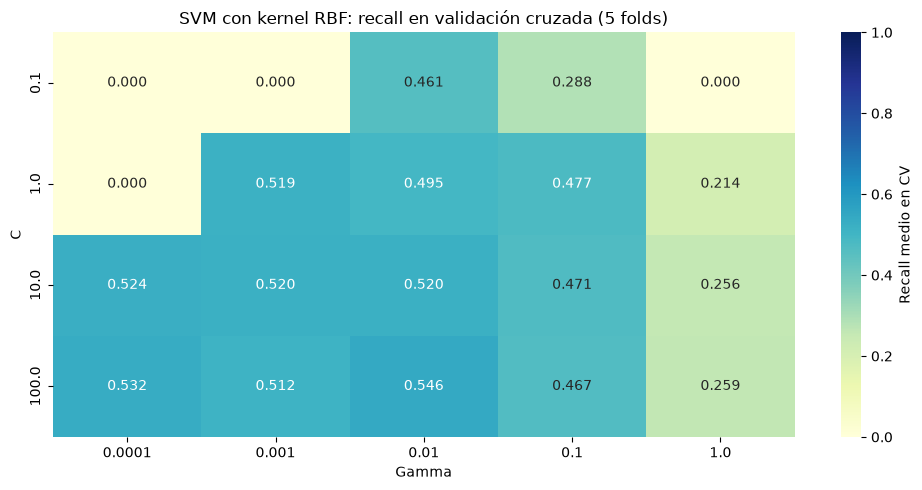

In [8]:
# El color representa el recall medio de las cinco particiones de validación.
cv_results_svm = pd.DataFrame(grid_svm.cv_results_)
heatmap_svm = cv_results_svm.pivot(
    index="param_svc__C", columns="param_svc__gamma", values="mean_test_score"
).astype(float).sort_index().sort_index(axis=1)

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    heatmap_svm, annot=True, fmt=".3f", cmap="YlGnBu",
    vmin=0, vmax=1, cbar_kws={"label": "Recall medio en CV"}, ax=ax,
)
ax.set(xlabel="Gamma", ylabel="C", title="SVM con kernel RBF: recall en validación cruzada (5 folds)")
plt.tight_layout()
plt.show()


Accuracy                   0.7693
Precision (Churn = Yes)    0.5714
Recall (Churn = Yes)       0.5241
F1 (Churn = Yes)           0.5467
ROC AUC                    0.7801

Reporte de clasificación:
                precision    recall  f1-score   support

Permanece (No)       0.83      0.86      0.85      1035
   Se va (Yes)       0.57      0.52      0.55       374

      accuracy                           0.77      1409
     macro avg       0.70      0.69      0.70      1409
  weighted avg       0.76      0.77      0.77      1409



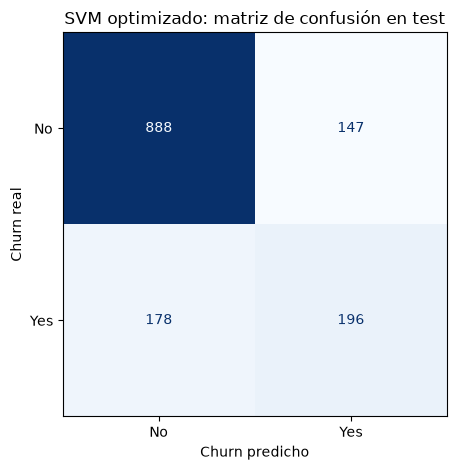

Detectamos 196 de 374 clientes que se fueron (52.4%).
Clientes que se fueron sin ser detectados: 178.
Clientes que permanecen pero fueron marcados como salida: 147.


In [9]:
# El mejor pipeline ya está reentrenado con todo el entrenamiento por refit=True.
y_pred_svm = best_svm.predict(X_test_svm)
y_score_svm = best_svm.decision_function(X_test_svm)

metrics_svm = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred_svm),
    "Precision (Churn = Yes)": precision_score(y_test, y_pred_svm, zero_division=0),
    "Recall (Churn = Yes)": recall_score(y_test, y_pred_svm),
    "F1 (Churn = Yes)": f1_score(y_test, y_pred_svm),
    "ROC AUC": roc_auc_score(y_test, y_score_svm),
}, name="SVM RBF — test")
print(metrics_svm.round(4).to_string())
print("\nReporte de clasificación:")
print(classification_report(
    y_test, y_pred_svm, labels=[0, 1],
    target_names=["Permanece (No)", "Se va (Yes)"], zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_svm, labels=[0, 1], display_labels=["No", "Yes"],
    cmap="Blues", colorbar=False,
)
plt.title("SVM optimizado: matriz de confusión en test")
plt.xlabel("Churn predicho")
plt.ylabel("Churn real")
plt.tight_layout()
plt.show()

tn_svm, fp_svm, fn_svm, tp_svm = confusion_matrix(y_test, y_pred_svm, labels=[0, 1]).ravel()
print(f"Detectamos {tp_svm} de {tp_svm + fn_svm} clientes que se fueron ({recall_score(y_test, y_pred_svm):.1%}).")
print(f"Clientes que se fueron sin ser detectados: {fn_svm}.")
print(f"Clientes que permanecen pero fueron marcados como salida: {fp_svm}.")


**Interpretación:** el recall mide qué proporción de los clientes que realmente se van logramos detectar. Un recall alto reduce los falsos negativos, pero debe revisarse junto con la precisión y los falsos positivos. El mejor resultado corresponde a la cuadrícula explorada, no a todos los valores posibles de C y gamma. El test no se utiliza para elegir hiperparámetros.

### ✅ Actividad 3: Clasificador y Optimización de Hiperparámetros Logistic Regression

Repita la actividad 2 pero con Logistic Regression. Bajo el mismo esquema de la actividad anterior, optimice el parámetro de regularización lambda. Utilice una transformación polinomial para garantizar fronteras de decisión no lineal. Compare sus resultados con los obtenidos de la actividad anterior

#### Regresión logística con características polinomiales

Usamos `PolynomialFeatures(degree=2, include_bias=False)` para incorporar cuadrados e interacciones entre características. Esto permite fronteras no lineales en el espacio original, aunque el modelo sigue siendo lineal respecto de las características transformadas.

Buscamos siete valores de **lambda** en escala logarítmica, desde 0.001 hasta 1000. Para esta búsqueda expresamos la fuerza de regularización como **lambda = 1 / C**, donde `C` es el parámetro inverso de regularización de scikit-learn: una lambda mayor implica regularización más fuerte. La escala exacta de lambda depende de cómo se normalice la función de pérdida.

Mantenemos el mismo test y las mismas cinco particiones estratificadas de la actividad 2. Dentro de cada fold se ajustan la imputación, el escalado inicial y el escalado posterior a la expansión polinomial. La selección se basa únicamente en recall de validación; `refit=True` reentrena el mejor pipeline con todo el entrenamiento.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from joblib import parallel_config

# Mismas entradas que SVM, con los faltantes originales de TotalCharges.
X_train_lr = X_train_svm.copy()
X_test_lr = X_test_svm.copy()

lr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("poly_scaler", StandardScaler()),
    # Con lbfgs se utiliza la regularización L2 predeterminada.
    ("lr", LogisticRegression(max_iter=20000, solver="lbfgs")),
])

lambda_values = np.logspace(-3, 3, 7)
param_grid_lr = {"lr__C": (1.0 / lambda_values).tolist()}
grid_lr = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid_lr,
    scoring="recall",
    cv=cv,
    refit=True,
    n_jobs=4,
    error_score="raise",
)
# Limitar hilos por proceso evita saturar el equipo al paralelizar los folds.
with parallel_config(backend="loky", inner_max_num_threads=1):
    grid_lr.fit(X_train_lr, y_train)

best_lr = grid_lr.best_estimator_
best_C_lr = grid_lr.best_params_["lr__C"]
best_lambda_lr = 1.0 / best_C_lr
print(f"Mejor lambda (1/C): {best_lambda_lr:g}")
print(f"Mejor C: {best_C_lr:g}")
print(f"Mejor recall promedio en CV: {grid_lr.best_score_:.4f}")
print(f"Desviación estándar en CV: {grid_lr.cv_results_['std_test_score'][grid_lr.best_index_]:.4f}")
print(f"Características después de la expansión: {best_lr.named_steps['poly'].n_output_features_}")
print(f"Iteraciones del modelo final: {best_lr.named_steps['lr'].n_iter_[0]}")


Mejor lambda (1/C): 10
Mejor C: 0.1
Mejor recall promedio en CV: 0.5492
Desviación estándar en CV: 0.0301
Características después de la expansión: 860
Iteraciones del modelo final: 112


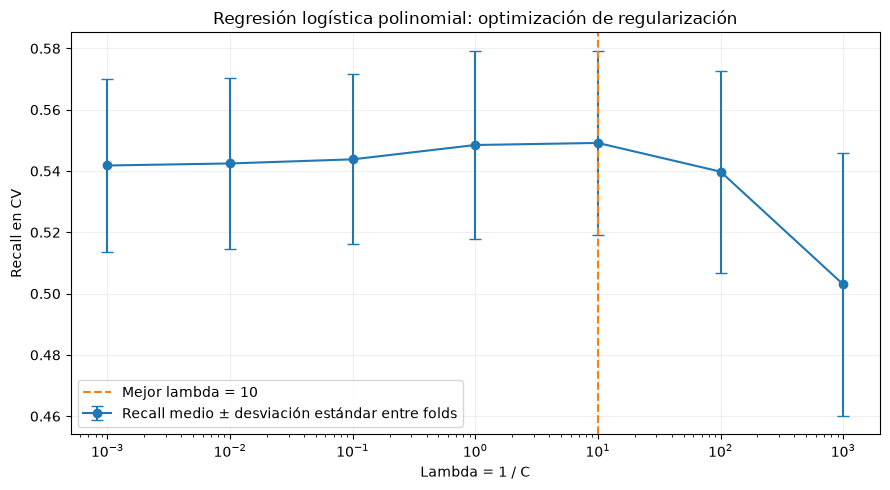

In [11]:
# Al optimizar un solo parámetro, una curva es más clara que un mapa 2D.
cv_results_lr = pd.DataFrame(grid_lr.cv_results_)
cv_results_lr["lambda"] = 1.0 / cv_results_lr["param_lr__C"].astype(float)
lambda_results = cv_results_lr.sort_values("lambda")

fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(
    lambda_results["lambda"], lambda_results["mean_test_score"],
    yerr=lambda_results["std_test_score"], fmt="o-", capsize=4,
    label="Recall medio ± desviación estándar entre folds",
)
ax.axvline(best_lambda_lr, color="tab:orange", linestyle="--", label=f"Mejor lambda = {best_lambda_lr:g}")
ax.set(xscale="log", xlabel="Lambda = 1 / C", ylabel="Recall en CV",
       title="Regresión logística polinomial: optimización de regularización")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()


Reporte de clasificación de LR:
                precision    recall  f1-score   support

Permanece (No)       0.84      0.88      0.86      1035
   Se va (Yes)       0.61      0.53      0.57       374

      accuracy                           0.78      1409
     macro avg       0.72      0.70      0.71      1409
  weighted avg       0.78      0.78      0.78      1409



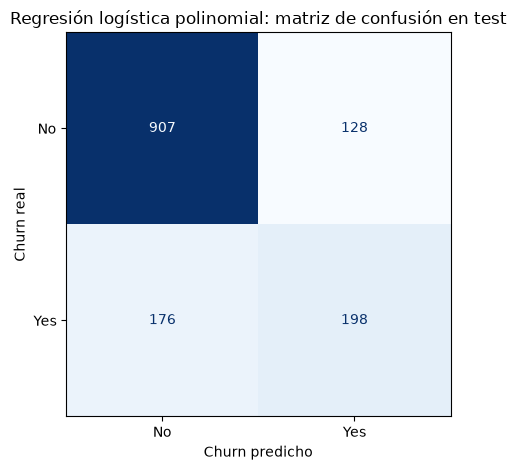

Comparación en el mismo conjunto de test:
                         SVM RBF — test  LR polinomial — test
Accuracy                         0.7693                0.7842
Precision (Churn = Yes)          0.5714                0.6074
Recall (Churn = Yes)             0.5241                0.5294
F1 (Churn = Yes)                 0.5467                0.5657
ROC AUC                          0.7801                0.8309

Recall CV — SVM: 0.5458; LR: 0.5492
LR detectó 198 de 374 clientes que se fueron; SVM detectó 196.
Falsos negativos — LR: 176; SVM: 178.
Falsos positivos — LR: 128; SVM: 147.
Diferencia de recall LR − SVM: +0.53 puntos porcentuales.


In [12]:
y_pred_lr = best_lr.predict(X_test_lr)
y_score_lr = best_lr.predict_proba(X_test_lr)[:, 1]
metrics_lr = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Precision (Churn = Yes)": precision_score(y_test, y_pred_lr, zero_division=0),
    "Recall (Churn = Yes)": recall_score(y_test, y_pred_lr),
    "F1 (Churn = Yes)": f1_score(y_test, y_pred_lr),
    "ROC AUC": roc_auc_score(y_test, y_score_lr),
}, name="LR polinomial — test")
print("Reporte de clasificación de LR:")
print(classification_report(
    y_test, y_pred_lr, labels=[0, 1],
    target_names=["Permanece (No)", "Se va (Yes)"], zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr, labels=[0, 1], display_labels=["No", "Yes"],
    cmap="Blues", colorbar=False,
)
plt.title("Regresión logística polinomial: matriz de confusión en test")
plt.xlabel("Churn predicho")
plt.ylabel("Churn real")
plt.tight_layout()
plt.show()

comparison_svm_lr = pd.concat([metrics_svm, metrics_lr], axis=1)
print("Comparación en el mismo conjunto de test:")
print(comparison_svm_lr.round(4).to_string())
print(f"\nRecall CV — SVM: {grid_svm.best_score_:.4f}; LR: {grid_lr.best_score_:.4f}")

tn_lr, fp_lr, fn_lr, tp_lr = confusion_matrix(y_test, y_pred_lr, labels=[0, 1]).ravel()
print(f"LR detectó {tp_lr} de {tp_lr + fn_lr} clientes que se fueron; SVM detectó {tp_svm}.")
print(f"Falsos negativos — LR: {fn_lr}; SVM: {fn_svm}.")
print(f"Falsos positivos — LR: {fp_lr}; SVM: {fp_svm}.")
recall_diff_pp = 100 * (metrics_lr["Recall (Churn = Yes)"] - metrics_svm["Recall (Churn = Yes)"])
print(f"Diferencia de recall LR − SVM: {recall_diff_pp:+.2f} puntos porcentuales.")


**Lectura de la comparación:** priorizamos recall porque buscamos detectar clientes que abandonan el servicio. También revisamos precisión y falsos positivos para valorar cuántas alertas serían incorrectas. La expansión polinomial aumenta la flexibilidad y el número de características, por lo que la regularización es especialmente relevante.

Las barras de la curva muestran la desviación estándar entre folds, no un intervalo de confianza. Las diferencias de test son descriptivas de esta partición y no demuestran superioridad estadística. No reajustamos lambda en función del test.

### ✅ Actividad 4: Bayesian Optimization

Repetir la actividad 2 usando Bayesian Optimization

Tip: usar BayesSearchCV

https://machinelearningmastery.com/scikit-optimize-for-hyperparameter-tuning-in-machine-learning/


#### Optimización bayesiana del SVM con kernel RBF

`BayesSearchCV` utiliza los resultados de evaluaciones anteriores para proponer nuevas combinaciones de hiperparámetros. Exploramos **C entre 0.1 y 100** y **gamma entre 0.0001 y 1**, con distribuciones log-uniformes, los mismos límites de la cuadrícula de la actividad 2.

El presupuesto es de **20 combinaciones × 5 folds = 100 ajustes**, más el reentrenamiento final. Las primeras cinco propuestas inicializan la búsqueda; después se utiliza un modelo sustituto de proceso gaussiano. Conservamos el mismo `StratifiedKFold`, el recall como objetivo y el pipeline de imputación y escalado. El test no interviene en la búsqueda.

A diferencia de GridSearch, las propuestas pueden tomar valores intermedios dentro de los rangos. Igualar el número de evaluaciones no implica igual tiempo de ejecución ni garantiza que la búsqueda bayesiana encuentre un mejor resultado.

In [13]:
from sklearn.base import clone
from skopt import BayesSearchCV
from skopt.space import Real

search_spaces_svm = {
    "svc__C": Real(0.1, 100.0, prior="log-uniform"),
    "svc__gamma": Real(0.0001, 1.0, prior="log-uniform"),
}
bayes_svm = BayesSearchCV(
    estimator=clone(svm_pipeline),
    search_spaces=search_spaces_svm,
    n_iter=20,
    scoring="recall",
    cv=cv,
    refit=True,
    n_jobs=4,
    n_points=1,
    random_state=42,
    optimizer_kwargs={"base_estimator": "GP", "n_initial_points": 5},
    error_score="raise",
)
with parallel_config(backend="loky", inner_max_num_threads=1):
    bayes_svm.fit(X_train_svm, y_train)

best_svm_bayes = bayes_svm.best_estimator_
print("Mejores hiperparámetros:", dict(bayes_svm.best_params_))
print(f"Mejor recall promedio en CV: {bayes_svm.best_score_:.4f}")
print(f"Desviación estándar en CV: {bayes_svm.cv_results_['std_test_score'][bayes_svm.best_index_]:.4f}")
print(f"Combinaciones evaluadas: {len(bayes_svm.cv_results_['params'])}")


Mejores hiperparámetros: {'svc__C': 100.0, 'svc__gamma': 0.010023689594136593}
Mejor recall promedio en CV: 0.5445
Desviación estándar en CV: 0.0217
Combinaciones evaluadas: 20


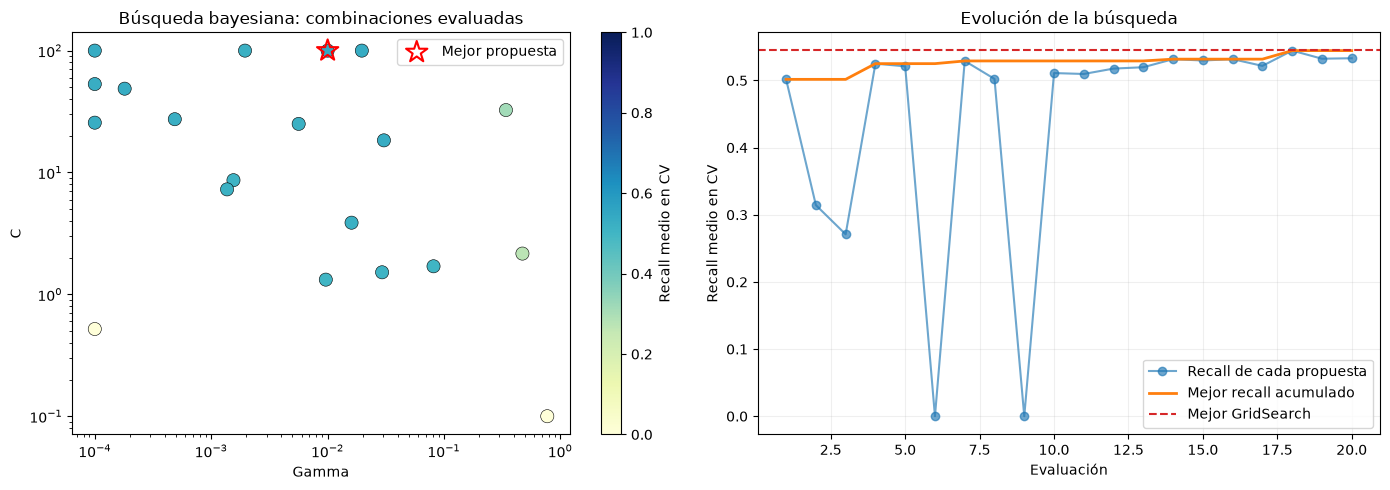

In [14]:
bayes_results_svm = pd.DataFrame(bayes_svm.cv_results_)
bayes_results_svm["C"] = bayes_results_svm["param_svc__C"].astype(float)
bayes_results_svm["gamma"] = bayes_results_svm["param_svc__gamma"].astype(float)
bayes_results_svm["evaluacion"] = np.arange(1, len(bayes_results_svm) + 1)

# Mapa de color de puntos evaluados: no se inventan scores entre propuestas.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
points = axes[0].scatter(
    bayes_results_svm["gamma"], bayes_results_svm["C"],
    c=bayes_results_svm["mean_test_score"], cmap="YlGnBu",
    vmin=0, vmax=1, s=90, edgecolors="black", linewidths=0.4,
)
axes[0].scatter(
    bayes_svm.best_params_["svc__gamma"], bayes_svm.best_params_["svc__C"],
    marker="*", s=260, facecolors="none", edgecolors="red",
    linewidths=1.5, label="Mejor propuesta",
)
axes[0].set(xscale="log", yscale="log", xlabel="Gamma", ylabel="C",
            title="Búsqueda bayesiana: combinaciones evaluadas")
axes[0].legend()
fig.colorbar(points, ax=axes[0], label="Recall medio en CV")

axes[1].plot(bayes_results_svm["evaluacion"], bayes_results_svm["mean_test_score"],
             "o-", alpha=0.65, label="Recall de cada propuesta")
axes[1].plot(bayes_results_svm["evaluacion"], bayes_results_svm["mean_test_score"].cummax(),
             linewidth=2, label="Mejor recall acumulado")
axes[1].axhline(grid_svm.best_score_, color="tab:red", linestyle="--", label="Mejor GridSearch")
axes[1].set(xlabel="Evaluación", ylabel="Recall medio en CV", title="Evolución de la búsqueda")
axes[1].legend()
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()


Reporte de clasificación de SVM bayesiano:
                precision    recall  f1-score   support

Permanece (No)       0.83      0.86      0.85      1035
   Se va (Yes)       0.57      0.52      0.55       374

      accuracy                           0.77      1409
     macro avg       0.70      0.69      0.70      1409
  weighted avg       0.76      0.77      0.77      1409



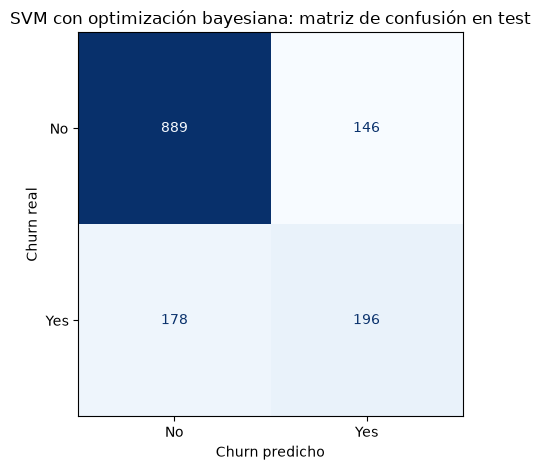

Comparación final en el mismo test:
                         SVM RBF — test  LR polinomial — test  SVM Bayes — test
Accuracy                         0.7693                0.7842            0.7700
Precision (Churn = Yes)          0.5714                0.6074            0.5731
Recall (Churn = Yes)             0.5241                0.5294            0.5241
F1 (Churn = Yes)                 0.5467                0.5657            0.5475
ROC AUC                          0.7801                0.8309            0.7801

Recall CV — Grid SVM: 0.5458; Grid LR: 0.5492; Bayes SVM: 0.5445
SVM bayesiano detectó 196 de 374 abandonos.
Falsos negativos: 178; falsos positivos: 146.
Diferencia de recall Bayes − Grid SVM: +0.00 puntos porcentuales.


In [15]:
# refit=True ya reentrenó la mejor configuración con todo el entrenamiento.
y_pred_svm_bayes = best_svm_bayes.predict(X_test_svm)
y_score_svm_bayes = best_svm_bayes.decision_function(X_test_svm)
metrics_svm_bayes = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred_svm_bayes),
    "Precision (Churn = Yes)": precision_score(y_test, y_pred_svm_bayes, zero_division=0),
    "Recall (Churn = Yes)": recall_score(y_test, y_pred_svm_bayes),
    "F1 (Churn = Yes)": f1_score(y_test, y_pred_svm_bayes),
    "ROC AUC": roc_auc_score(y_test, y_score_svm_bayes),
}, name="SVM Bayes — test")
print("Reporte de clasificación de SVM bayesiano:")
print(classification_report(
    y_test, y_pred_svm_bayes, labels=[0, 1],
    target_names=["Permanece (No)", "Se va (Yes)"], zero_division=0,
))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_svm_bayes, labels=[0, 1], display_labels=["No", "Yes"],
    cmap="Blues", colorbar=False,
)
plt.title("SVM con optimización bayesiana: matriz de confusión en test")
plt.xlabel("Churn predicho")
plt.ylabel("Churn real")
plt.tight_layout()
plt.show()

comparison_final = pd.concat([metrics_svm, metrics_lr, metrics_svm_bayes], axis=1)
print("Comparación final en el mismo test:")
print(comparison_final.round(4).to_string())
print(f"\nRecall CV — Grid SVM: {grid_svm.best_score_:.4f}; Grid LR: {grid_lr.best_score_:.4f}; Bayes SVM: {bayes_svm.best_score_:.4f}")
tn_bayes, fp_bayes, fn_bayes, tp_bayes = confusion_matrix(y_test, y_pred_svm_bayes, labels=[0, 1]).ravel()
print(f"SVM bayesiano detectó {tp_bayes} de {tp_bayes + fn_bayes} abandonos.")
print(f"Falsos negativos: {fn_bayes}; falsos positivos: {fp_bayes}.")
print(f"Diferencia de recall Bayes − Grid SVM: {100 * (metrics_svm_bayes['Recall (Churn = Yes)'] - metrics_svm['Recall (Churn = Yes)']):+.2f} puntos porcentuales.")


**Interpretación:** la búsqueda bayesiana concentra las nuevas evaluaciones según lo aprendido de las anteriores, mientras que GridSearch evalúa una cuadrícula fija. El mapa muestra únicamente los puntos realmente evaluados, con gamma en el eje horizontal, C en el vertical y recall como color; no es una malla completa ni una superficie interpolada.

La comparación de test permite describir recall, precisión y errores de los modelos seleccionados por CV. Un mejor recall de validación no garantiza un mejor recall de test. Las diferencias dependen de esta partición, los rangos y el presupuesto de búsqueda; no demuestran una superioridad universal de un método. No se modifica la búsqueda a partir del resultado del test.

## Reflexión final y posibles mejoras

Los modelos identificaron patrones útiles para predecir el abandono, pero su capacidad para detectar a todos los clientes que se van fue limitada. La regresión logística con expansión polinomial obtuvo el mayor recall en test, de aproximadamente **53 %**, y un **ROC AUC de 0,83**. Esto sugiere que existe información predictiva en las características disponibles, aunque la decisión final de clasificación deja sin detectar a casi la mitad de los abandonos.

Estos resultados no permiten concluir por sí solos que exista *underfitting*. Para comprobarlo sería necesario comparar el rendimiento en entrenamiento y validación, además de construir curvas de aprendizaje. El desbalance de clases también puede influir: los modelos se entrenaron sin ponderar las clases y utilizaron su regla de decisión predeterminada. Aunque seleccionamos los hiperparámetros según recall, esto no modifica directamente la función de entrenamiento ni optimiza el umbral de clasificación.

Como siguientes pasos, propongo:

- **Ajustar el umbral de decisión** mediante la curva precisión–recall, utilizando predicciones de validación. Un umbral menor podría detectar más abandonos, a cambio de generar más falsas alarmas.
- **Probar `class_weight="balanced"`** y evaluar si dar mayor peso a la clase minoritaria mejora ese equilibrio.
- **Comparar regresión logística con y sin expansión polinomial**, manteniendo el mismo procedimiento, para medir el aporte real de los términos no lineales.
- **Analizar las curvas de aprendizaje y los errores** para distinguir entre falta de ejemplos, capacidad insuficiente del modelo y limitaciones de las características.
- **Explorar otros modelos**, como métodos basados en árboles y boosting, con el mismo esquema de validación.

Respecto a los datos, contar con más registros no garantiza una mejora si estos contienen la misma información limitada. El abandono puede depender de factores que no estén representados en el conjunto disponible, como incidencias recientes, cambios de consumo, aumentos de tarifa o experiencias con soporte. Incorporar estas variables y su evolución temporal podría ser más útil que aumentar únicamente la cantidad de clientes. Cualquier nueva característica debe estar disponible antes del momento en que se pretende predecir el abandono, para evitar fuga de información.

Finalmente, las mejoras deben seleccionarse dentro de la validación, sin utilizar el test para ajustar decisiones. Como este conjunto de test ya fue consultado al comparar los modelos, una evaluación final de nuevas decisiones se beneficiaría de un conjunto adicional no utilizado o de validación anidada. El objetivo práctico sería detectar más clientes en riesgo manteniendo una cantidad de falsas alarmas compatible con el costo de las acciones de retención.